In [1]:
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.pyplot import FuncFormatter

from shared import (
    BARD_RATE,
    convolve_sequences,
    mixture_distribution,
    relative_d2,
    thousands_formatter,
    set_custom_style,
)

# Set custom plot style
set_custom_style()

['#5842ff', '#ff4000', '#00b368']

In [2]:
def sample_damage_distribution(d2, l_c, p, multiplier, size, n_hits):
    damage_amounts = [d2, int(d2 * l_c), int(d2 * 1.25), int(d2 * l_c * 1.25)]

    random_hits = np.random.choice(damage_amounts, p=p, size=size * n_hits)
    random_hits = (
        np.random.uniform(0.95, 1.050001, size=size * n_hits) * random_hits
    ).astype(int) * multiplier

    random_hits = random_hits.reshape((size, n_hits)).sum(axis=1)

## Refulgent Arrow procs

In [3]:
def sample_refulgent_arrow(n, n_samples: int) -> np.ndarray:
    """Sample number of Refulgent Arrow procs.

    Parameters
    ----------
    n : _type_
        Number of Burst Shot / Refulgent Arrow actions for a sequence.
    n_samples : int
        Number of sequences to sample

    Returns
    -------
    samples : np.ndarray
        (n_samples, n) Array of Burst Shot (0) and Refulgent Arrow (1) procs from sampling.
    """
    samples = np.zeros(shape=(n_samples, n))

    for i in range(n_samples):
        for j in range(n):
            if j == 0:
                prev = 0
            else:
                prev = samples[i, j - 1]
            samples[i, j] = np.random.binomial(1, 0.35) if prev == 0 else 0
    return samples

### Refulgent Arrow proc distribution

In [4]:
def p_refulgent(n: int, k: int, p: float = 0.35):
    """Probability distribution of attaining k Refulgent Arrow procs for a sequence
    of n HA / RA GCDs.

    Parameters
    ----------
    n : int
        Number of GCDs in the HA / RA sequence
    k : int
        Number of RA procs granted, must be <= n
    p : float, optional
        RA proc probability, by default 0.35

    Returns
    -------
    float
        Probability of getting k RA procs

    Raises
    ------
    ValueError
        k > n
    """
    if k > n:
        raise ValueError(f"k ({k}) must be <= n ({n}).")
    # count sequences ending in 0: a_{n,k,0} = C(n-k+1, k) - C(n-k, k-1)
    a0 = comb(n - k + 1, k) - (comb(n - k, k - 1) if k >= 1 else 0)
    # count sequences ending in 1: a_{n,k,1} = C(n-k, k-1)
    a1 = comb(n - k, k - 1) if k >= 1 else 0

    # probability contributions
    term_0 = a0 * (p**k) * ((1 - p) ** (n - 2 * k))
    term_1 = a1 * (p**k) * ((1 - p) ** (n - 2 * k + 1))

    return term_0 + term_1

Proc distribution plot

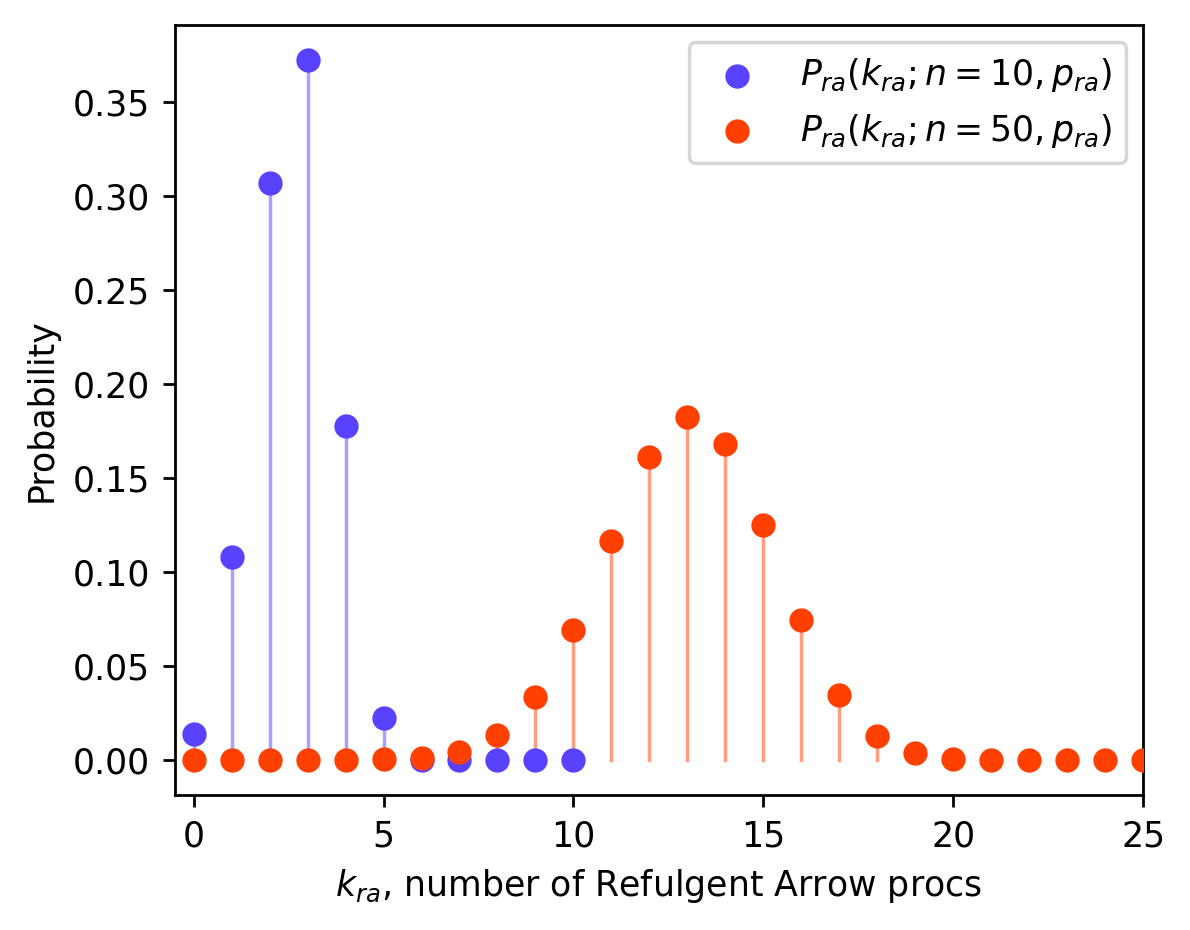

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=250)
for idx, a in enumerate([10, 50]):
    pmf = {k: p_refulgent(a, k) for k in range(a + 1)}

    # Create stems (vertical lines) from x-axis to each point
    for k, p_val in pmf.items():
        ax.plot([k, k], [0, p_val], color=f"C{idx}", alpha=0.5, linewidth=1)

    # Plot points on top of stems
    ax.scatter(
        pmf.keys(),
        pmf.values(),
        label=rf"$P_{{ra}}(k_{{ra}}; n = {a}, p_{{ra}})$",
        zorder=3,
    )

ax.set_xlabel(r"$k_{ra}$, number of Refulgent Arrow procs")
ax.set_ylabel("Probability")
ax.set_xlim([-0.5, 25])
plt.legend()
plt.savefig("../tex/img/ra-proc-distribution.png")
plt.show()

### RA damage distribution

In [6]:
print("Critical hit multiplier:", BARD_RATE.l_c)
print("p_n: ", BARD_RATE.p[0])
print("p_c: ", BARD_RATE.p[1])
print("p_d: ", BARD_RATE.p[2])
print("p_cd:", BARD_RATE.p[3])


Critical hit multiplier: 1585.0
p_n:  0.52632
p_c:  0.16168
p_d:  0.23868
p_cd: 0.07332


In [7]:
d2_ha = relative_d2(220)
d2_ra = relative_d2(280)

test = sample_refulgent_arrow(14, 1000)

sub_sequences = {0: [0], 1: [1, 2, 3, 4], 2: [5], 3: [6, 7, 8, 9, 10, 11, 12, 13]}

sub_sequence_dh = {0: 0.2, 1: 0.2, 2: 0, 3: 0}

sub_sequence_ch = {0: 0.02, 1: 0.02, 2: 0.02, 3: 0.02}

mult = round(1.06 * 1.15, 4)

sub_sequence_multiplier = {
    0: 1.0,
    1: mult,
    2: mult,
    3: 1.0,
}

In [8]:
def sample_damage(d2, n_hits, n_samples, p, l_c, multiplier):
    hit_damage = [d2, int(d2 * l_c), int(d2 * 1.25), int(d2 * l_c * 1.25)]

    random_hits = np.random.choice(hit_damage, p=p, size=n_samples * n_hits)
    random_hits = (
        np.random.uniform(0.95, 1.050001, size=n_samples * n_hits)
        * random_hits
        * multiplier
    ).astype(int)

    random_hits = random_hits.reshape((n_samples, n_hits)).sum(axis=1)

    return random_hits

Sample RA proc sequences 1000 times and then sample the proc counts of each sub-sequence 10000 times for damage variability. Not the smartest way to do it, but it works.

In [9]:
n_inner_samples = 10000
n_ra_samples = 1000
sub_sequence_arrays = {}
aaa1 = np.zeros(shape=(n_inner_samples, n_ra_samples))
aaa2 = np.zeros(shape=(n_inner_samples, n_ra_samples))


for ss_idx, ra_idx in sub_sequences.items():
    # ss_idx = 1
    for i in range(n_ra_samples):
        ss = test[i, sub_sequences[ss_idx]]

        n_ha = ss[ss == 0].size
        n_ra = ss[ss == 1].size

        p = BARD_RATE.get_p(sub_sequence_ch[ss_idx], sub_sequence_dh[ss_idx])
        multiplier = sub_sequence_multiplier[ss_idx]

        aaa1[:, i] = sample_damage(
            d2_ha,
            n_ha,
            n_inner_samples,
            p,
            BARD_RATE.l_c / 1000,
            multiplier,
        )
        aaa2[:, i] = sample_damage(
            d2_ra,
            n_ra,
            n_inner_samples,
            p,
            BARD_RATE.l_c / 1000,
            multiplier,
        )
        sub_sequence_arrays[ss_idx] = aaa1 + aaa2


# sns.histplot(sample_damage(10000, n_ha, 100000, p, rate.l_c / 1000, sub_sequence_multiplier[ss_idx]))


Compute damage variability exactly, convolve over all possible proc counts for each sub-sequence.

In [10]:
from ffxiv_stats.moments import Rotation


def make_ra_record(n, p, multiplier, action_name_append: str = ""):
    return {
        "n": n,
        "d2": d2_ra,
        "action_name": "Refulgent Arrow" + action_name_append,
        "base_action": "Refulgent Arrow",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": BARD_RATE.l_c,
        "buffs": multiplier,
        "is_dot": False,
    }


def make_ha_record(n, p, multiplier, action_name_append: str = ""):
    return {
        "n": n,
        "d2": d2_ha,
        "action_name": "Burst Shot" + action_name_append,
        "base_action": "Burst Shot",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": BARD_RATE.l_c,
        "buffs": multiplier,
        "is_dot": False,
    }


rotation_list = []
for s_idx, s in sub_sequences.items():
    rotation_list_inner = []

    n = len(s)
    p = BARD_RATE.get_p(sub_sequence_ch[s_idx], sub_sequence_dh[s_idx])
    multiplier = sub_sequence_multiplier[s_idx]

    for k in range(0, (n + 1) // 2 + 1):
        ra_record = make_ra_record(k, p, multiplier)
        ha_record = make_ha_record(n - k, p, multiplier)

        record_list = []
        if ra_record["n"] > 0:
            record_list.append(ra_record)
        if ha_record["n"] > 0:
            record_list.append(ha_record)

        rotation_df = pd.DataFrame(record_list)
        rotation_list_inner.append(Rotation(rotation_df, 1, 1, 1, 1))
    rotation_list.append(rotation_list_inner)

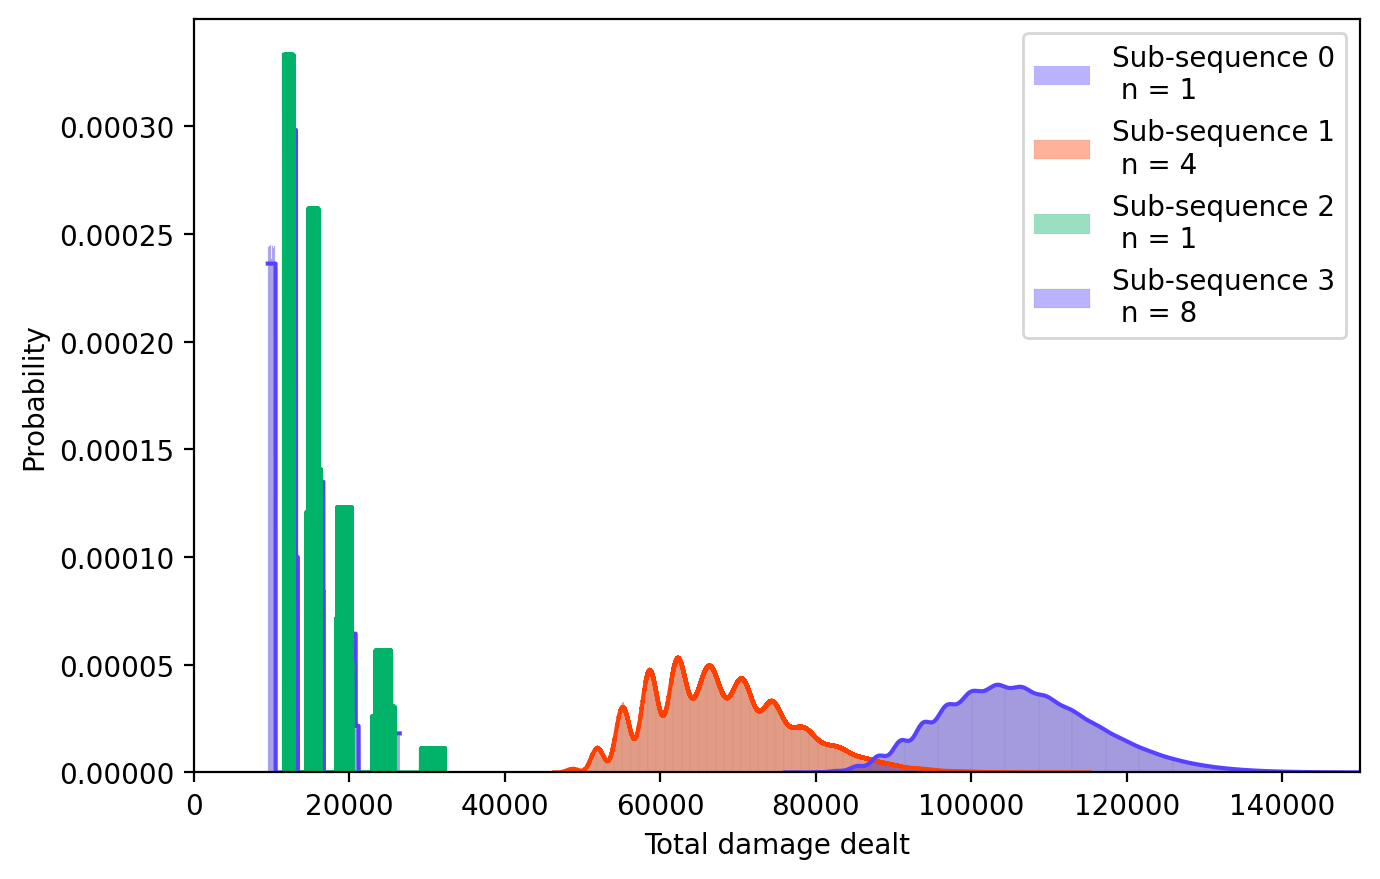

In [11]:
mixture = []
for idx, r in enumerate(rotation_list):
    n = len(sub_sequences[idx])
    w = [p_refulgent(n, x) for x in range((n + 1) // 2 + 1)]
    mixture.append(mixture_distribution(r, w))

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5), dpi=200)
[ax.plot(m[1], m[0]) for m in mixture]
[
    sns.histplot(
        s.ravel(),
        stat="density",
        color=f"C{idx}",
        alpha=0.4,
        ax=ax,
        label=f"Sub-sequence {idx}\n n = {len(sub_sequences[idx])}",
    )
    for idx, s in enumerate(sub_sequence_arrays.values())
]
ax.set_xlim([0, 150000])
ax.legend()
ax.set_ylabel("Probability")
ax.set_xlabel("Total damage dealt")
plt.tight_layout()
plt.savefig("../tex/img/supp-hara.png")
plt.show()

### No proc RNG comparison

In [12]:
mean_proc = []

for idx, r in enumerate(sub_sequences):
    n = len(sub_sequences[idx])
    w = [p_refulgent(n, x) for x in range((n + 1) // 2 + 1)]
    mean_proc.append(np.argmax(w))

record_list = []

for s_idx, s in sub_sequences.items():
    rotation_list_inner = []

    n = len(s)
    k = mean_proc[s_idx]
    p = BARD_RATE.get_p(sub_sequence_ch[s_idx], sub_sequence_dh[s_idx])
    multiplier = sub_sequence_multiplier[s_idx]

    ra_record = make_ra_record(k, p, multiplier, f"-sequence-{s_idx}")
    ha_record = make_ha_record(n - k, p, multiplier, f"-sequence-{s_idx}")

    if ra_record["n"] > 0:
        record_list.append(ra_record)
    if ha_record["n"] > 0:
        record_list.append(ha_record)


no_proc_rotation_df = pd.DataFrame(record_list)
no_proc_rotation = Rotation(no_proc_rotation_df, 1, 1, 1, 1)

Compare everything

In [13]:
pmf, support = convolve_sequences(mixture)

mu = np.trapezoid(pmf * support)
var = np.trapezoid(pmf * support**2) - mu**2
std = np.sqrt(var)

no_proc_rotation_mean = no_proc_rotation.rotation_mean
no_proc_rotation_std = no_proc_rotation.rotation_std

print(
    "sigma percent change: ", 100 * (std - no_proc_rotation_std) / no_proc_rotation_std
)

fig, ax = plt.subplots(1, 1, dpi=200, figsize=(5, 4))
# Plot the analytical distribution
ax.plot(support, pmf, label=f"HA / RA proc RNG\nμ={mu:.0f}, σ={std:.0f}")

# Plot the empirical samples
sns.histplot(
    np.sum([s.ravel() for s in sub_sequence_arrays.values()], axis=0),
    stat="density",
    alpha=0.5,
    ax=ax,
    label="Sampling",
)

no_proc_rotation.plot_rotation_distribution(
    ax=ax,
    label=f"Fixed HA / RA proc rate\nμ={no_proc_rotation_mean:.0f}, σ={no_proc_rotation_std:.0f}",
)
ax.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax.set_xlabel("Total Damage")
ax.set_ylabel("Probability")
ax.legend()
ax.set_xlim([145000, 310000])
plt.tight_layout()
plt.savefig("../tex/img/ra-dmg-distribution.png")
plt.show()

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\Craig\AppData\Roaming\Python\Python311\site-packages\IPython\core\interactiveshell.py", line 3508, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "C:\Users\Craig\AppData\Local\Temp\ipykernel_41708\4217548743.py", line 1, in <module>
    pmf, support = convolve_sequences(mixture)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Craig\Documents\ffxiv-repos\damage_variability_papers\04_approximate_damage_model_bard\src\shared.py", line 65, in convolve_sequences
  File "C:\Users\Craig\AppData\Roaming\Python\Python311\site-packages\numpy\__init__.py", line 328, in __getattr__
    raise AttributeError("module {!r} has no attribute "
AttributeError: module 'numpy' has no attribute 'trapezoid'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "C:\Users\Craig\AppData\Roaming\Python\Python311\site-packages\IPython\core\interactiveshell.py", li